In [1]:
import pandas as pd

df = pd.read_csv("../data/automobile_prices_economics_2019_2023.csv")

print(df.head())
print(df.isnull().sum())

  Month/Year New Price ($) Used Price ($) Inflation Rate (%)  \
0     19-Jan        25,000         18,000              1.60%   
1     19-Feb        25,000         17,900              1.50%   
2     19-Mar        25,000         17,800              1.90%   
3     19-Apr        25,000         17,700              2.00%   
4     19-May        25,000         17,600              1.80%   

  Interest Rate (%) Units Sold  
0             2.40%     28,500  
1             2.40%     29,000  
2             2.40%     31,500  
3             2.40%     30,000  
4             2.40%     32,000  
Month/Year            1
New Price ($)         1
Used Price ($)        1
Inflation Rate (%)    1
Interest Rate (%)     1
Units Sold            1
dtype: int64


In [2]:
df = df.dropna()
print(df.isnull().sum())
df.info()

Month/Year            0
New Price ($)         0
Used Price ($)        0
Inflation Rate (%)    0
Interest Rate (%)     0
Units Sold            0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Month/Year          60 non-null     str  
 1   New Price ($)       60 non-null     str  
 2   Used Price ($)      60 non-null     str  
 3   Inflation Rate (%)  60 non-null     str  
 4   Interest Rate (%)   60 non-null     str  
 5   Units Sold          60 non-null     str  
dtypes: str(6)
memory usage: 2.9 KB


In [3]:
df['New Price ($)'] = pd.to_numeric(df['New Price ($)'].str.replace(',', ''))
df['Used Price ($)'] = pd.to_numeric(df['Used Price ($)'].str.replace(',', ''))
df['Units Sold'] = pd.to_numeric(df['Units Sold'].str.replace(',', ''))

df['Inflation Rate (%)'] = pd.to_numeric(df['Inflation Rate (%)'].str.replace('%', ''))
df['Interest Rate (%)'] = pd.to_numeric(df['Interest Rate (%)'].str.replace('%', ''))

print(df.head())
df.info()

  Month/Year  New Price ($)  Used Price ($)  Inflation Rate (%)  \
0     19-Jan          25000           18000                 1.6   
1     19-Feb          25000           17900                 1.5   
2     19-Mar          25000           17800                 1.9   
3     19-Apr          25000           17700                 2.0   
4     19-May          25000           17600                 1.8   

   Interest Rate (%)  Units Sold  
0                2.4       28500  
1                2.4       29000  
2                2.4       31500  
3                2.4       30000  
4                2.4       32000  
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Month/Year          60 non-null     str    
 1   New Price ($)       60 non-null     int64  
 2   Used Price ($)      60 non-null     int64  
 3   Inflation Rate (%)  60 non-null     float64
 4

In [4]:
df['Month/Year'] = pd.to_datetime(df['Month/Year'], format='%y-%b')
print(df.head())
df.info()

  Month/Year  New Price ($)  Used Price ($)  Inflation Rate (%)  \
0 2019-01-01          25000           18000                 1.6   
1 2019-02-01          25000           17900                 1.5   
2 2019-03-01          25000           17800                 1.9   
3 2019-04-01          25000           17700                 2.0   
4 2019-05-01          25000           17600                 1.8   

   Interest Rate (%)  Units Sold  
0                2.4       28500  
1                2.4       29000  
2                2.4       31500  
3                2.4       30000  
4                2.4       32000  
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Month/Year          60 non-null     datetime64[us]
 1   New Price ($)       60 non-null     int64         
 2   Used Price ($)      60 non-null     int64         
 3   Inflation R

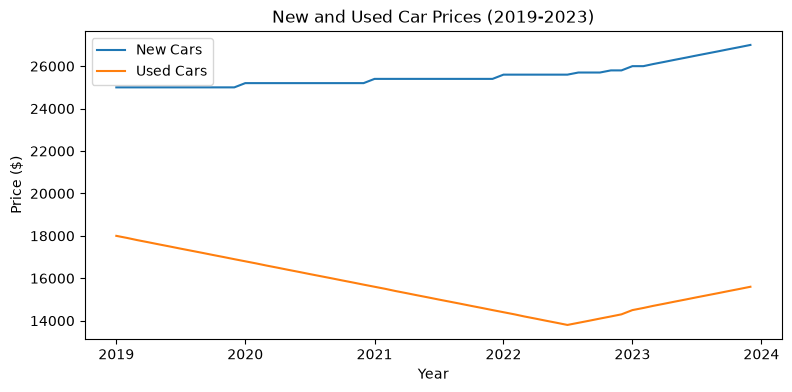

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(df['Month/Year'], df['New Price ($)'], label='New Cars')
ax.plot(df['Month/Year'], df['Used Price ($)'], label='Used Cars')

ax.set_title('New and Used Car Prices (2019-2023)')
ax.set_xlabel('Year')
ax.set_ylabel('Price ($)')
ax.legend()

plt.show()

The new car prices gradually increased between the yeaars 2019 and 2023 while the used car priced decreased from 2019 until about the middle of 2022 when they prices for the used cars began to rise. 

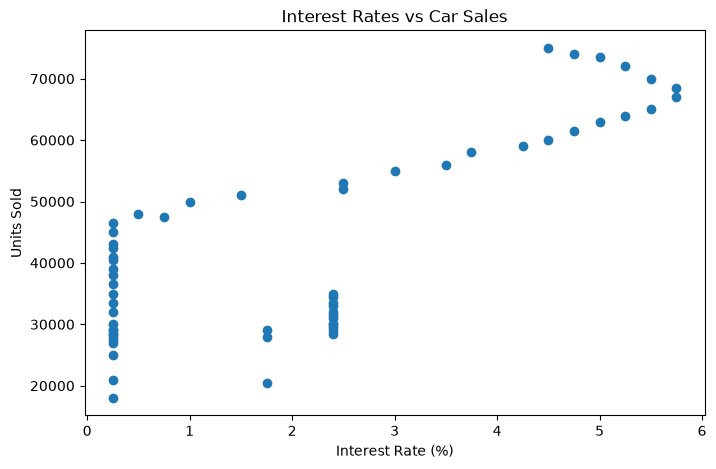

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df['Interest Rate (%)'], df['Units Sold'])

ax.set_title('Interest Rates vs Car Sales')
ax.set_xlabel('Interest Rate (%)')
ax.set_ylabel('Units Sold')

plt.show()

The graph shows that in general the higher the intrest rates were assosiated with higher numbers of car sales. This is a little surprising as higher intrest rates usually make borrowing somewhat more expensive. But this does not mean that the higher intrest rates caused and increase in the sales.

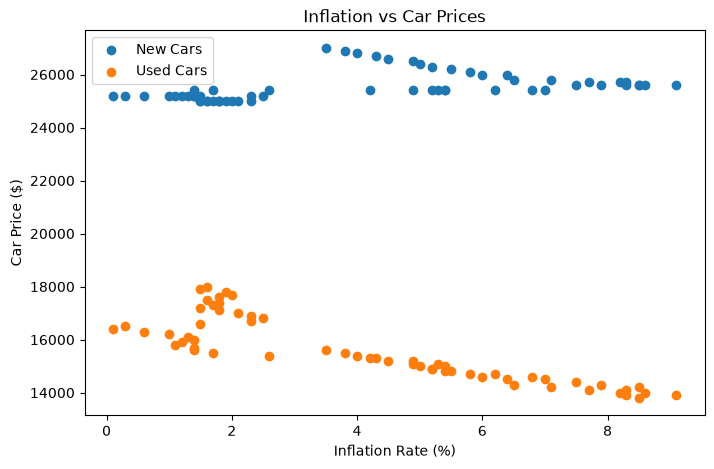

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df['Inflation Rate (%)'], df['New Price ($)'], label='New Cars')
ax.scatter(df['Inflation Rate (%)'], df['Used Price ($)'], label='Used Cars')

ax.set_title('Inflation vs Car Prices')
ax.set_xlabel('Inflation Rate (%)')
ax.set_ylabel('Car Price ($)')
ax.legend()

plt.show()

The used car prices appeard loweer when the inflation rates were higher. The new car prices doesnt quite have the same relationship being more stable between the price and inflation rates meaning the increase in inflation rates is proabably due to other factors. 